# Profiling · Calidad de datos · World Happiness 2015-2019

**Perfilado de calidad (EDA):** revisión de los 5 CSV originales **antes** de limpiar.

Revisa nulos, duplicados, nombres y tipos de columnas, diferencias de esquema entre años, ceros, outliers y nombres de país, y cierra con las observaciones de calidad y la propuesta de esquema unificado.

Este notebook es **solo diagnóstico**: no modifica datos ni escribe archivos. Las funciones están definidas aquí mismo, en la sección donde se usan, para que se pueda leer y ejecutar de arriba hacia abajo.
Las relaciones entre variables (correlaciones, distribución del target, efecto del año) se estudian en `eda.ipynb`, sobre el dataset ya unificado.

## 0. Configuración

In [1]:
import re
from difflib import SequenceMatcher

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from happiness_etl.config import (
    COLUMN_MAP_BY_YEAR, COUNTRY, FEATURES, TARGET, UNIFIED_COLUMNS, YEAR, YEARS,
)
from happiness_etl.extract import read_all

NUMERIC_COLUMNS = (*FEATURES, TARGET)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")

## 1. Carga y comparación de esquemas
Los archivos se cargan tal cual vienen (`extract.read_all`). Ningún archivo trae columna de año: se conoce por el nombre del archivo.

In [2]:
crudos = read_all()
pd.DataFrame({
    "filas": {a: df.shape[0] for a, df in crudos.items()},
    "columnas": {a: df.shape[1] for a, df in crudos.items()},
})

,filas,columnas
2015,158,12
2016,157,13
2017,155,12
2018,156,9
2019,156,9


Matriz de presencia: qué columna (con su nombre original) aparece en cada año.

In [3]:
def column_presence(frames: dict[int, pd.DataFrame]) -> pd.DataFrame:
    """Matriz columna original x año: True si la columna existe ese año."""
    columns = sorted({c for df in frames.values() for c in df.columns})
    return pd.DataFrame(
        {year: [c in df.columns for c in columns] for year, df in frames.items()},
        index=columns,
    )


column_presence(crudos).map(lambda v: "✓" if v else "")

,2015,2016,2017,2018,2019
Country,✓,✓,✓,,
Country or region,,,,✓,✓
Dystopia Residual,✓,✓,,,
Dystopia.Residual,,,✓,,
Economy (GDP per Capita),✓,✓,,,
Economy..GDP.per.Capita.,,,✓,,
Family,✓,✓,✓,,
Freedom,✓,✓,✓,,
Freedom to make life choices,,,,✓,✓
GDP per capita,,,,✓,✓


Tipos de datos por columna y año.

In [4]:
pd.DataFrame({anio: df.dtypes.astype(str) for anio, df in crudos.items()}).fillna("")

,2015,2016,2017,2018,2019
Country,str,str,str,,
Country or region,,,,str,str
Dystopia Residual,float64,float64,,,
Dystopia.Residual,,,float64,,
Economy (GDP per Capita),float64,float64,,,
Economy..GDP.per.Capita.,,,float64,,
Family,float64,float64,float64,,
Freedom,float64,float64,float64,,
Freedom to make life choices,,,,float64,float64
GDP per capita,,,,float64,float64


## 2. Equivalencias entre años
Cada concepto tiene hasta tres nombres distintos. La tabla de equivalencias vive en `config.COLUMN_MAP_BY_YEAR`
(una prueba de pytest verifica que cada nombre exista en su CSV). Los nombres canónicos coinciden con el contrato del evento.

In [5]:
def equivalence_table() -> pd.DataFrame:
    """Nombre original de cada columna canónica en cada año (según config)."""
    table = {}
    for year, mapping in COLUMN_MAP_BY_YEAR.items():
        inverse = {canon: orig for orig, canon in mapping.items()}
        table[year] = {c: inverse.get(c, "") for c in UNIFIED_COLUMNS if c != YEAR}
    return pd.DataFrame(table)


equivalence_table()

,2015,2016,2017,2018,2019
country,Country,Country,Country,Country or region,Country or region
gdp,Economy (GDP per Capita),Economy (GDP per Capita),Economy..GDP.per.Capita.,GDP per capita,GDP per capita
family,Family,Family,Family,Social support,Social support
health,Health (Life Expectancy),Health (Life Expectancy),Health..Life.Expectancy.,Healthy life expectancy,Healthy life expectancy
freedom,Freedom,Freedom,Freedom,Freedom to make life choices,Freedom to make life choices
generosity,Generosity,Generosity,Generosity,Generosity,Generosity
corruption,Trust (Government Corruption),Trust (Government Corruption),Trust..Government.Corruption.,Perceptions of corruption,Perceptions of corruption
happiness_score,Happiness Score,Happiness Score,Happiness.Score,Score,Score


Para comparar años se usa una **vista alineada**: columnas canónicas y `year`.
Es solo una vista de diagnóstico; no trata nulos ni corrige valores (eso será `clean.py`).

In [6]:
def aligned_view(frames: dict[int, pd.DataFrame]) -> pd.DataFrame:
    """Vista larga con nombres canónicos y columna year, SOLO para comparar años.

    No es la limpieza: no trata nulos ni corrige valores (eso va en clean.py).
    """
    parts = []
    for year, df in frames.items():
        mapping = COLUMN_MAP_BY_YEAR[year]
        part = df[list(mapping)].rename(columns=mapping)
        part.insert(1, YEAR, year)
        parts.append(part)
    return pd.concat(parts, ignore_index=True)[list(UNIFIED_COLUMNS)]


alineado = aligned_view(crudos)
print(alineado.shape)
alineado.head()

(782, 9)


,country,year,gdp,family,health,freedom,generosity,corruption,happiness_score
0,Switzerland,2015,1.397,1.350,0.941,0.666,0.297,0.420,7.587
1,Iceland,2015,1.302,1.402,0.948,0.629,0.436,0.141,7.561
2,Denmark,2015,1.325,1.361,0.875,0.649,0.341,0.484,7.527
3,Norway,2015,1.459,1.331,0.885,0.670,0.347,0.365,7.522
4,Canada,2015,1.326,1.323,0.906,0.633,0.458,0.330,7.427


## 3. Calidad por año
### 3.1 Nulos

In [7]:
def missing_summary(frames: dict[int, pd.DataFrame]) -> pd.DataFrame:
    """Nulos por año: filas, celdas nulas y columnas afectadas."""
    out = {}
    for year, df in frames.items():
        nulls = df.isna().sum()
        out[year] = {
            "rows": len(df),
            "null_cells": int(nulls.sum()),
            "columns_with_nulls": ", ".join(nulls[nulls > 0].index) or "-",
        }
    return pd.DataFrame(out).T


missing_summary(crudos)

,rows,null_cells,columns_with_nulls
2015,158,0,-
2016,157,0,-
2017,155,0,-
2018,156,1,Perceptions of corruption
2019,156,0,-


In [8]:
# Filas con algún nulo en la vista alineada
alineado[alineado.isna().any(axis=1)]

,country,year,gdp,family,health,freedom,generosity,corruption,happiness_score
489,United Arab Emirates,2018,2.096,0.776,0.67,0.284,0.186,NaN,6.774


### 3.2 Duplicados y nombres de país

In [9]:
def _country_column(year: int) -> str:
    """Nombre original de la columna de país en un año."""
    return next(orig for orig, canon in COLUMN_MAP_BY_YEAR[year].items() if canon == COUNTRY)


def duplicate_summary(frames: dict[int, pd.DataFrame]) -> pd.DataFrame:
    """Duplicados por año: filas idénticas y países repetidos (exactos y sin mayúsculas)."""
    out = {}
    for year, df in frames.items():
        raw_names = df[_country_column(year)].astype(str)
        names = raw_names.str.strip()
        out[year] = {
            "duplicated_rows": int(df.duplicated().sum()),
            "duplicated_countries": int(names.duplicated().sum()),
            "duplicated_countries_ignoring_case": int(names.str.lower().duplicated().sum()),
            "names_with_extra_spaces": int((raw_names != names).sum()),
        }
    return pd.DataFrame(out).T


duplicate_summary(crudos)

,duplicated_rows,duplicated_countries,duplicated_countries_ignoring_case,names_with_extra_spaces
2015,0,0,0,0
2016,0,0,0,0
2017,0,0,0,0
2018,0,0,0,0
2019,0,0,0,0


### 3.3 Perfil numérico por variable y año
Sirve para comparar escalas entre años y detectar ceros sospechosos.

In [10]:
def numeric_profile(aligned: pd.DataFrame) -> pd.DataFrame:
    """Mínimo, máximo, media, desviación, ceros y nulos por variable y año."""
    rows = []
    for year, group in aligned.groupby(YEAR):
        for col in NUMERIC_COLUMNS:
            s = group[col]
            rows.append({
                "variable": col, YEAR: year,
                "min": s.min(), "max": s.max(), "mean": s.mean(), "std": s.std(),
                "zeros": int((s == 0).sum()), "nulls": int(s.isna().sum()),
            })
    return pd.DataFrame(rows).set_index(["variable", YEAR])


def range_checks(aligned: pd.DataFrame) -> pd.Series:
    """Violaciones de rango esperado: puntaje entre 0 y 10, variables no negativas."""
    target = aligned[TARGET]
    return pd.Series({
        "target_outside_0_10": int(((target < 0) | (target > 10)).sum()),
        "negative_feature_values": int((aligned[list(FEATURES)] < 0).sum().sum()),
    })


perfil = numeric_profile(alineado)
perfil

,,min,max,mean,std,zeros,nulls
variable,year,,,,,,
gdp,2015,0.000,1.690,0.846,0.403,1,0
family,2015,0.000,1.402,0.991,0.272,1,0
health,2015,0.000,1.025,0.630,0.247,1,0
freedom,2015,0.000,0.670,0.429,0.151,1,0
generosity,2015,0.000,0.796,0.237,0.127,1,0
corruption,2015,0.000,0.552,0.143,0.120,1,0
happiness_score,2015,2.839,7.587,5.376,1.145,0,0
gdp,2016,0.000,1.824,0.954,0.413,1,0
family,2016,0.000,1.183,0.794,0.267,1,0


In [11]:
range_checks(alineado)

target_outside_0_10        0
negative_feature_values    0
dtype: int64

In [12]:
# Ceros por variable y año (un 0 puede ser un dato faltante codificado)
perfil["zeros"].unstack(YEAR)

year,2015,2016,2017,2018,2019
variable,,,,,
corruption,1,1,1,2,1
family,1,1,1,1,1
freedom,1,1,1,1,1
gdp,1,1,1,1,1
generosity,1,1,1,1,1
happiness_score,0,0,0,0,0
health,1,1,1,1,1


In [13]:
# Filas con algún cero en las variables explicativas
alineado[(alineado[list(FEATURES)] == 0).any(axis=1)]

,country,year,gdp,family,health,freedom,generosity,corruption,happiness_score
73,Indonesia,2015,0.828,1.087,0.638,0.466,0.515,0.000,5.399
101,Greece,2015,1.154,0.929,0.882,0.077,0.000,0.014,4.857
111,Iraq,2015,0.985,0.819,0.602,0.000,0.179,0.138,4.677
119,Congo (Kinshasa),2015,0.000,1.001,0.098,0.226,0.248,0.076,4.517
122,Sierra Leone,2015,0.330,0.956,0.000,0.408,0.215,0.088,4.507
147,Central African Republic,2015,0.079,0.000,0.067,0.489,0.238,0.083,3.678
233,Somalia,2016,0.000,0.336,0.115,0.568,0.272,0.312,5.440
244,Bosnia and Herzegovina,2016,0.934,0.644,0.708,0.095,0.299,0.000,5.163
256,Greece,2016,1.249,0.755,0.800,0.058,0.000,0.041,5.033
268,Sierra Leone,2016,0.365,0.628,0.000,0.307,0.239,0.082,4.635


### 3.4 Outliers (regla IQR, calculada dentro de cada año)

In [14]:
def iqr_outliers(aligned: pd.DataFrame, k: float = 1.5) -> pd.DataFrame:
    """Valores fuera de [Q1 - k*IQR, Q3 + k*IQR], calculado dentro de cada año."""
    rows = []
    for year, group in aligned.groupby(YEAR):
        for col in NUMERIC_COLUMNS:
            s = group[col]
            q1, q3 = s.quantile([0.25, 0.75])
            low, high = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
            for idx in s[(s < low) | (s > high)].index:
                rows.append({
                    YEAR: year, "variable": col, COUNTRY: group.at[idx, COUNTRY],
                    "value": s[idx], "side": "low" if s[idx] < low else "high",
                })
    return pd.DataFrame(rows, columns=[YEAR, "variable", COUNTRY, "value", "side"])


outliers = iqr_outliers(alineado)
outliers.pivot_table(index="variable", columns=YEAR, values="value", aggfunc="count", fill_value=0)

year,2015,2016,2017,2018,2019
variable,,,,,
corruption,14,12,13,17,14
family,3,1,4,3,4
freedom,0,0,0,2,1
gdp,0,0,0,1,0
generosity,2,4,2,2,2
health,0,0,0,0,1


In [15]:
outliers.sort_values(["variable", YEAR, "value"])

,year,variable,country,value,side
7,2015,corruption,Norway,0.365,high
15,2015,corruption,Hong Kong,0.371,high
11,2015,corruption,Luxembourg,0.378,high
17,2015,corruption,Georgia,0.383,high
12,2015,corruption,United Arab Emirates,0.386,high
...,...,...,...,...,...
61,2018,generosity,Indonesia,0.484,high
62,2018,generosity,Myanmar,0.598,high
86,2019,generosity,Indonesia,0.498,high
87,2019,generosity,Myanmar,0.566,high


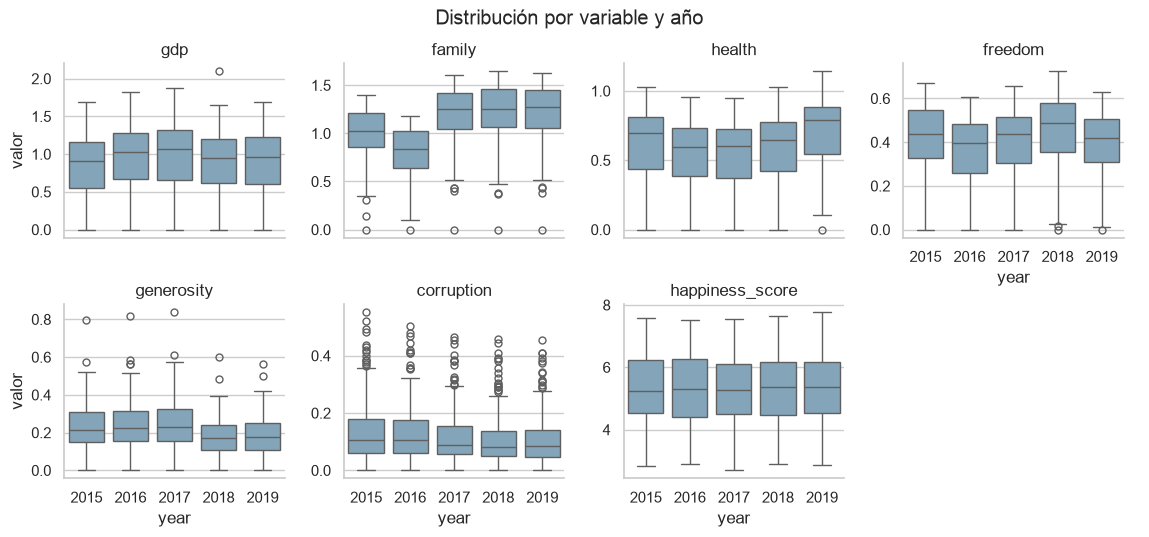

In [16]:
largo = alineado.melt(id_vars=[COUNTRY, YEAR], value_vars=list(NUMERIC_COLUMNS),
                      var_name="variable", value_name="valor")
g = sns.catplot(data=largo, x=YEAR, y="valor", col="variable", col_wrap=4,
                kind="box", sharey=False, height=2.6, aspect=1.1, color="#7aa6c2")
g.set_titles("{col_name}")
g.figure.suptitle("Distribución por variable y año", y=1.03)
plt.show()

## 4. Países
### 4.1 Cobertura por año

In [17]:
def country_coverage(aligned: pd.DataFrame) -> pd.DataFrame:
    """Matriz país x año (True si aparece) con el número de años de cada país."""
    names = aligned[COUNTRY].astype(str).str.strip()
    matrix = pd.crosstab(names, aligned[YEAR]).astype(bool)
    matrix["n_years"] = matrix.sum(axis=1)
    return matrix.sort_values(["n_years"]).rename_axis(index=COUNTRY, columns=None)


cobertura = country_coverage(alineado)
cobertura["n_years"].value_counts().sort_index().rename("paises")

n_years
1      9
2      4
3      4
4     12
5    141
Name: paises, dtype: int64

In [18]:
# Países que no aparecen en los 5 años
cobertura[cobertura["n_years"] < len(YEARS)].map(lambda v: "✓" if v is True else ("" if v is False else v))

,2015,2016,2017,2018,2019,n_years
country,,,,,,
Gambia,,,,,✓,1
"Hong Kong S.A.R., China",,,✓,,,1
Djibouti,✓,,,,,1
Oman,✓,,,,,1
Puerto Rico,,✓,,,,1
North Macedonia,,,,,✓,1
Somaliland region,✓,,,,,1
Somaliland Region,,✓,,,,1
Taiwan Province of China,,,✓,,,1


### 4.2 Posibles variantes del mismo país
Pares de nombres que nunca coinciden en el mismo año y se parecen (uno contiene al otro o similitud de texto ≥ 0.8).
Es una ayuda para revisar a mano, no una regla automática.

In [19]:
def _normalize(name: str) -> str:
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9]+", " ", name.lower())).strip()


def country_name_variants(coverage: pd.DataFrame, cutoff: float = 0.8) -> pd.DataFrame:
    """Pares de nombres que podrían ser el mismo país escrito distinto.

    Solo compara países que no están en todos los años y cuyos años NO se cruzan
    (si aparecen el mismo año, son países distintos). Marca un par si un nombre
    contiene al otro o si su similitud de texto es >= cutoff. Es una ayuda para
    revisar a mano, no una regla automática.
    """
    years = [y for y in YEARS if y in coverage.columns]
    partial = coverage[coverage["n_years"] < len(years)]
    present = {name: {y for y in years if partial.at[name, y]} for name in partial.index}
    rows = []
    names = list(partial.index)
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            if present[a] & present[b]:
                continue
            na, nb = _normalize(a), _normalize(b)
            similarity = SequenceMatcher(None, na, nb).ratio()
            contained = na in nb or nb in na
            if contained or similarity >= cutoff:
                rows.append({
                    "name_a": a, "years_a": sorted(present[a]),
                    "name_b": b, "years_b": sorted(present[b]),
                    "similarity": round(similarity, 2), "contained": contained,
                })
    result = pd.DataFrame(rows, columns=["name_a", "years_a", "name_b", "years_b", "similarity", "contained"])
    return result.sort_values("similarity", ascending=False, ignore_index=True)


country_name_variants(cobertura)

,name_a,years_a,name_b,years_b,similarity,contained
0,Somaliland region,[2015],Somaliland Region,[2016],1.00,True
1,Northern Cyprus,"[2018, 2019]",North Cyprus,"[2015, 2016, 2017]",0.89,False
2,Trinidad & Tobago,"[2018, 2019]",Trinidad and Tobago,"[2015, 2016, 2017]",0.88,False
3,North Macedonia,[2019],Macedonia,"[2015, 2016, 2017, 2018]",0.75,True
4,"Hong Kong S.A.R., China",[2017],Hong Kong,"[2015, 2016, 2018, 2019]",0.60,True
5,Taiwan Province of China,[2017],Taiwan,"[2015, 2016, 2018, 2019]",0.40,True


## 5. Observaciones de calidad y esquema unificado propuesto

### 5.1 Hallazgos y tratamiento propuesto

| # | Hallazgo | Evidencia | Tratamiento propuesto | Etapa |
|---|----------|-----------|-----------------------|-------|
| 1 | Cada concepto tiene hasta 3 nombres de columna distintos según el año | §1, §2 | Mapa de nombres por año en `config`, con nombres canónicos | `clean` |
| 2 | Los archivos no traen el año | §1 | Agregar `year` a partir del archivo de origen | `clean` |
| 3 | Columnas que no se usan: rankings, `Region` (solo 2015-2016), error estándar, intervalos de confianza, *whiskers* y `Dystopia Residual` | §1 | No pasan al dataset unificado. El ranking y el residual dependen del puntaje, así que usarlos sería fuga del target. `Region` se evalúa como atributo de `dim_country` | `clean` |
| 4 | Un solo nulo: `corruption` de United Arab Emirates en 2018 | §3.1 | Interpolación lineal dentro del país: promedio de 2017 y 2019 (0.253). Solo entre años observados, sin extrapolar; se registra en el log y en el README | `transform` |
| 5 | Sin filas duplicadas ni países repetidos dentro de un año | §3.2 | Nada que corregir; `validate` lo comprueba igual | `validate` |
| 6 | 30 filas con algún cero; cada variable tiene exactamente un cero mínimo por año (dos en `corruption` 2018) | §3.3 | Conservar. Son valores mínimos de la escala, no datos faltantes | — |
| 7 | `family` y `health` cambian de escala entre años (p. ej. `family` pasa de 0.79 en 2016 a 1.19 en 2017), mientras el puntaje se mantiene estable | §3.3 | No se corrige en la limpieza. Se decide en el modelado si `year` entra como variable | Fase 3 |
| 8 | 102 valores fuera del rango IQR, la mayoría de `corruption` por el lado alto | §3.4 | Conservar. Es la distribución real del dataset (valores plausibles), no errores | — |
| 9 | 6 países escritos de forma distinta según el año: 170 nombres para 164 países | §4 | Unificar al nombre más frecuente (ver 5.2) | `transform` |

### 5.2 Efecto de unificar los nombres de país (simulación)
Solo para comprobar la regla; la transformación real irá en `transform.py`.
Se usa el nombre que aparece en más años. `Somaliland` queda empatado (1 año cada uno) y se elige `Somaliland Region`.

In [20]:
NOMBRE_CANONICO = {
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Northern Cyprus": "North Cyprus",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "North Macedonia": "Macedonia",
    "Somaliland region": "Somaliland Region",
}

simulado = alineado.assign(**{COUNTRY: alineado[COUNTRY].replace(NOMBRE_CANONICO)})
cobertura_simulada = simulado.groupby(COUNTRY)[YEAR].nunique()

pd.Series({
    "filas": len(simulado),
    "paises_antes": alineado[COUNTRY].nunique(),
    "paises_despues": simulado[COUNTRY].nunique(),
    "paises_en_los_5_anios": int((cobertura_simulada == len(YEARS)).sum()),
    "pares_pais_anio_duplicados": int(simulado.duplicated([COUNTRY, YEAR]).sum()),
})

filas                         782
paises_antes                  170
paises_despues                164
paises_en_los_5_anios         146
pares_pais_anio_duplicados      0
dtype: int64

### 5.3 Esquema unificado propuesto
Una fila por país y año (782 filas). Estos nombres coinciden con el contrato del evento; el puntaje se llama `actual_happiness_score` solo dentro del evento.

In [21]:
pd.DataFrame(
    [
        (COUNTRY, "str", "No", "Nombre canónico del país (5.2)"),
        (YEAR, "int", "No", "Entre 2015 y 2019; viene del archivo de origen"),
        ("gdp", "float", "No", "≥ 0"),
        ("family", "float", "No", "≥ 0 (en 2018-2019 es 'Social support')"),
        ("health", "float", "No", "≥ 0"),
        ("freedom", "float", "No", "≥ 0"),
        ("generosity", "float", "No", "≥ 0"),
        ("corruption", "float", "No", "≥ 0; el nulo de UAE 2018 se imputa en `transform`"),
        (TARGET, "float", "No", "Entre 0 y 10; es el target, nunca una variable explicativa"),
    ],
    columns=["columna", "tipo", "admite_nulos", "regla"],
).set_index("columna")

,tipo,admite_nulos,regla
columna,,,
country,str,No,Nombre canónico del país (5.2)
year,int,No,Entre 2015 y 2019; viene del archivo de origen
gdp,float,No,≥ 0
family,float,No,≥ 0 (en 2018-2019 es 'Social support')
health,float,No,≥ 0
freedom,float,No,≥ 0
generosity,float,No,≥ 0
corruption,float,No,≥ 0; el nulo de UAE 2018 se imputa en `transform`
happiness_score,float,No,"Entre 0 y 10; es el target, nunca una variable..."


**Reglas de validación derivadas** (se implementan en `validate.py`): columnas exactamente las del esquema; sin nulos; `year` en 2015-2019; variables explicativas ≥ 0; puntaje entre 0 y 10; par (`country`, `year`) único.

**Decisiones tomadas:** interpolación lineal por país para el nulo de UAE; nombre más frecuente para los países (queda `Macedonia`); se conservan ceros y outliers.